# 05 - Model 2: Machine Learning

*Part 1 is the team's feature notebook `03_feature_dataset` (original code; inputs and the Model 1 events from
`data/processed/`, file saves removed). Part 2 is the modelling.*

## Business understanding for Model 2

**Why a second model?** Model 1 (notebook 04) only finds what its rule describes: *one step
that lasts too long*. A loss could also look different - a step of normal length at an unusual moment, or an unusual
combination of timing and parallel activity. Model 2 asks:

> *Are there activations that look abnormal in a multi-feature view and that the rule does not flag - and are any
> of them genuine performance losses?*

**What ML cannot do here:** nobody labelled the recording, so there is no **ground truth** (verified answers). No
supervised model can be trained, and true accuracy cannot be measured. Only **unsupervised** methods are possible
(the course table lists clustering for unsupervised anomaly detection).

**An anomaly is not a loss:** an anomaly is *rare*; a performance loss is *lost production time*. Every ML candidate
has to pass the evidence rules of notebook 01.

## Setup

Imports, parameters (the same values as `config.yaml`) and the hand-over of results between the notebooks (`data/processed/`, run the notebooks in order 01-06).

In [1]:
from io import StringIO
from pathlib import Path

from IPython.display import Image, display
import numpy as np
import pandas as pd
from dataclasses import dataclass, field
import re
from scipy import stats as sps
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score, average_precision_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from itertools import combinations
import dataclasses
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Patch

%matplotlib inline
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

In [2]:
# Parameters - the same values as config.yaml
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = {'paths': {'raw_siemens': 'data/raw/Beispieldatensatz Siemens S7 SPS.csv',
           'raw_beckhoff': 'data/raw/Beispieldatensatz Beckhoff SPS.csv',
           'variable_file': 'data/raw/Variablenerklärung.xlsx',
           'reports_dir': 'reports',
           'figures_dir': 'reports/figures'},
 'timebase': {'gap_report_s': 0.5,
              'gap_cooccur_tolerance_s': 0.2,
              'resample_grids_ms': [20, 50, 76, 93, 100, 200, 500]},
 'phases': {'production_start_signal': 'E200.0',
            'curtain_signal': 'A201.0',
            'curtain_signal_beckhoff': 'VG.safeCurtainShort',
            'hmi_run_signal': 'Visual.start',
            'pallet_request_signals': ['WH.desiredPalletX', 'WH.desiredPalletY'],
            'drilling_cycle_register': 'MW22'},
 'rule': {'tukey_k': 3.0,
          'min_activations': 5,
          'min_excess_s': 'auto',
          'sweep_k': [1.5, 3.0],
          'sweep_min_excess_s': [1.0, 1.5, 1.84, 2.0, 2.5, 3.0, 4.0, 5.0],
          'sweep_merge_gap_s': [0.0, 1.0, 2.0, 5.0, 10.0],
          'merge_gap_s': 0.0},
 'ml': {'seeds': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
        'contamination_sweep': [0.01, 0.02, 0.05, 0.1],
        'kmeans_k': [2, 3, 4, 5, 6, 7, 8],
        'top_k': 10},
 'performance': {'bootstrap_resamples': 5000, 'bootstrap_seed': 42}}
cfg["paths"] = {k: ROOT / v for k, v in cfg["paths"].items()}
PROCESSED = ROOT / "data" / "processed"        # prepared data handed from one notebook to the next
FIGURES = cfg["paths"]["figures_dir"]          # reports/figures

In [3]:
def save_stage(name, results):
    """Write this notebook's results to data/processed/<name>.pkl for the next notebooks."""
    PROCESSED.mkdir(parents=True, exist_ok=True)
    pd.to_pickle(results, PROCESSED / f"{name}.pkl")


def load_stage(name, notebook):
    """Results of an earlier notebook; a clear message names the notebook to run first."""
    f = PROCESSED / f"{name}.pkl"
    if not f.exists():
        raise FileNotFoundError(f"data/processed/{name}.pkl is missing - run notebook {notebook} first.")
    return pd.read_pickle(f)

**Data container**

- `PLCData`: Analysis-ready recording of one PLC.

In [4]:
@dataclass
class PLCData:
    """Analysis-ready recording of one PLC."""

    name: str
    frame: pd.DataFrame                 # timestamp, t, one column per signal
    signals: list[str]
    raw_shape: tuple[int, int]          # rows, signal columns (as in the file)
    excluded_rows: pd.DataFrame = field(default_factory=pd.DataFrame)
    dropped_columns: list[str] = field(default_factory=list)

In [5]:
s02 = load_stage("02_data", "02_data_understanding_and_cleaning")
s03 = load_stage("03_prepared", "03_data_preparation")
s04 = load_stage("04_model1", "04_model_1_engineering_detection")
data = {k: PLCData(**v) if k in ("Siemens", "Beckhoff") else v for k, v in s02.pop("data").items()}
ctx = {"cfg": cfg, "data": data, **s02, **s03, **s04}          # notebooks 02-04 (rule flags = reference labels only)
flags = ctx["flags"]
flag_keys = set(zip(flags["signal"], flags["start"]))

## Part 1 - The feature table: one row per actuator activation

*Source: team notebook `03_feature_dataset` - original code and notes.*

**Goal:** turn the two cleaned PLC recordings into one table with one row per *activation* (one continuous ON
period of an actuator output), plus features that say whether that activation took longer than normal.

**Why activations and not raw rows?** A raw row is a snapshot of the machine at one instant. "This step took too
long" only exists at the activation level.

**How the two PLCs are combined:** by *stacking* their activation records (`pd.concat`), not by joining raw rows.
Both timestamps are converted to seconds relative to the same start `T0` (hypothesis H1: the PLC clocks agree
within 0.09 s).

**Outputs** (kept in memory): `features` - model input (no labels, no answers); `labels` - reference events E1-E8
per activation (**evaluation only**, never a model input); `cycles` - pallet cycles 1-9 with their role.

In [6]:
import re
# inputs: the cleaned data (notebook 02) and the Model 1 events (notebook 04), both in memory
data = ctx["data"]

### 2. Load and build one shared time axis

`t` = seconds since the first Siemens sample. The same `T0` is used for both
PLCs, so a time of 252 s means the same moment in both tables.

In [7]:
sie = data["Siemens"].frame[["timestamp"] + data["Siemens"].signals].copy()
bec = data["Beckhoff"].frame[["timestamp"] + data["Beckhoff"].signals].copy()

T0 = sie["timestamp"].iloc[0]
sie["t"] = (sie["timestamp"] - T0) / 1000
bec["t"] = (bec["timestamp"] - T0) / 1000

# Production starts at the first press of the HMI reset button (E200.0,
# documented as "Reset button from HMI"), as in the performance-loss report.
PRODUCTION_START_S = sie.loc[sie["E200.0"].astype(bool), "t"].iloc[0]
print(f"Production start: {PRODUCTION_START_S:.3f} s")

print("Siemens :", sie.shape, f"t = {sie['t'].iloc[0]:.2f} .. {sie['t'].iloc[-1]:.2f} s")
print("Beckhoff:", bec.shape, f"t = {bec['t'].iloc[0]:.2f} .. {bec['t'].iloc[-1]:.2f} s")

Production start: 8.927 s
Siemens : (6282, 144) t = 0.00 .. 505.70 s
Beckhoff: (5197, 55) t = 0.41 .. 505.80 s


### 3. Choose the actuator outputs

- **Siemens:** columns starting with `A` whose station in the variable file is
  the sorting or drilling station. This leaves out `A200.x` / `A201.x` (data
  and safety bits sent to the Beckhoff PLC, station "Beckhoff"), `A6.x` (safety
  lamp outputs) and `AW256` (a 16-bit word). Constant columns are skipped.
- **Beckhoff:** columns containing `.Q`.

**Open point (ask the professor):** `WH.Q3_horRack` and
`WH.Q3_horizontal_towards_rack` (and the same for Q4-Q8) look like two names for
one output, but their values are **not identical**. Both are kept here and
marked with a shared `pair_id`, so nothing is silently dropped.

**Why `A200.x` is excluded:** the variable file documents these as data sent to
the Beckhoff PLC (for example "Oven and vacuum position data to Beckhoff"), not
as actuators. They stay ON for up to 264 s and would look like anomalies.
`A201.0` (safety data from the curtain to Beckhoff) is excluded for the same
reason.

In [8]:
sie_doc = pd.read_excel(cfg["paths"]["variable_file"], sheet_name="Siemens")
actuator_names = sie_doc.loc[
    sie_doc["Variablenname"].str.startswith("A")
    & sie_doc["Station"].isin(["Sorting station", "Drilling station"]),
    "Variablenname",
]
sie_outputs = [c for c in actuator_names if c in sie.columns and sie[c].nunique() > 1]
bec_outputs = [c for c in bec.columns if ".Q" in c and bec[c].nunique() > 1]

print("Siemens outputs :", len(sie_outputs))
print("Beckhoff outputs:", len(bec_outputs))

# Names of the same Beckhoff output: same station + Q number, e.g. 'WH.Q3'
def pair_key(signal):
    m = re.match(r"^((?:WH|VG)\.Q\d+)_", signal)
    return m.group(1) if m else signal

pair_counts = pd.Series([pair_key(c) for c in bec_outputs]).value_counts()
print("Beckhoff names that appear twice:", pair_counts[pair_counts > 1].index.tolist())

Siemens outputs : 19
Beckhoff outputs: 22
Beckhoff names that appear twice: ['WH.Q3', 'WH.Q4', 'WH.Q5', 'WH.Q6', 'WH.Q7', 'WH.Q8']


### 4. Extract activations

One activation = one continuous run of `True`. A signal that is already ON in
the first row, or still ON in the last row, is closed at the recording border
and flagged (`open_at_start`, `open_at_end`), because its true duration is
unknown.

In [9]:
def on_intervals(t, signal):
    """Return (start, end, open_at_start, open_at_end) for every ON period."""
    s = signal.astype(bool).to_numpy().astype(int)
    t = t.to_numpy()
    edge = np.diff(s, prepend=0, append=0)
    starts = np.where(edge == 1)[0]
    ends = np.where(edge == -1)[0]          # index of the first OFF row
    out = []
    for a, b in zip(starts, ends):
        end_t = t[b] if b < len(t) else t[-1]
        out.append((t[a], end_t, a == 0, b >= len(t)))
    return out


def interval_table(df, plc, columns):
    rows = [
        (plc, col, a, b, oas, oae)
        for col in columns
        for a, b, oas, oae in on_intervals(df["t"], df[col])
    ]
    return pd.DataFrame(
        rows, columns=["plc", "signal", "start", "end", "open_at_start", "open_at_end"]
    )


acts = pd.concat(
    [interval_table(sie, "Siemens", sie_outputs),
     interval_table(bec, "Beckhoff", bec_outputs)],
    ignore_index=True,
)
acts["duration_s"] = acts["end"] - acts["start"]
acts = acts.sort_values(["start", "plc", "signal"]).reset_index(drop=True)
acts.insert(0, "activation_id", np.arange(len(acts)))

print("Activations:", len(acts))
print(acts.groupby("plc").size().to_string())
print("Open at start / end:", acts["open_at_start"].sum(), "/", acts["open_at_end"].sum())
acts.head()

Activations: 680
plc
Beckhoff    482
Siemens     198
Open at start / end: 2 / 4


,activation_id,plc,signal,start,end,open_at_start,open_at_end,duration_s
0,0,Siemens,A4.1,0.000,31.764,True,False,31.764
1,1,Beckhoff,WH.Q8_cantBack,0.410,10.454,True,False,10.044
2,2,Beckhoff,WH.Q8_cantilever_backward,8.882,10.454,False,False,1.572
3,3,Siemens,A0.6,8.927,10.808,False,False,1.881
4,4,Siemens,A1.6,8.927,51.143,False,False,42.216


### 5. Pallet cycles

A new cycle starts whenever `WH.desiredPalletX` or `WH.desiredPalletY` changes
(Beckhoff). Cycle 1 starts at the beginning of the recording. Each activation
is assigned to the cycle that contains its **midpoint**; `crosses_cycle_boundary`
marks the ones that stick out so they can be inspected.

In [10]:
pos = bec[["t", "WH.desiredPalletX", "WH.desiredPalletY"]].reset_index(drop=True)
changed = (pos["WH.desiredPalletX"].diff().fillna(1) != 0) | \
          (pos["WH.desiredPalletY"].diff().fillna(1) != 0)

cycle_starts = pos.loc[changed, "t"].to_numpy().copy()
cycle_starts[0] = 0.0                      # cycle 1 covers the whole startup
recording_end = max(sie["t"].iloc[-1], bec["t"].iloc[-1])

cycles = pd.DataFrame({
    "cycle": np.arange(1, len(cycle_starts) + 1),
    "cycle_start": cycle_starts,
    "cycle_end": np.append(cycle_starts[1:], recording_end),
})
cycles["cycle_duration_s"] = cycles["cycle_end"] - cycles["cycle_start"]
cycles["rack_x"] = pos.loc[changed, "WH.desiredPalletX"].to_numpy()
cycles["rack_y"] = pos.loc[changed, "WH.desiredPalletY"].to_numpy()

last = cycles["cycle"].max()
cycles["cycle_role"] = np.where(
    cycles["cycle"] == 1, "startup",
    np.where(cycles["cycle"] == last, "truncated", "complete"))
cycles

,cycle,cycle_start,cycle_end,cycle_duration_s,rack_x,rack_y,cycle_role
0,1,0.000,45.432,45.432,1620,110,startup
1,2,45.432,98.497,53.065,910,110,complete
2,3,98.497,156.139,57.642,2330,540,complete
3,4,156.139,210.070,53.931,1640,540,complete
4,5,210.070,273.135,63.065,910,540,complete
5,6,273.135,336.267,63.132,2330,1030,complete
6,7,336.267,404.441,68.174,1620,1030,complete
7,8,404.441,452.992,48.551,910,1030,complete
8,9,452.992,505.804,52.812,2330,110,truncated


In [11]:
midpoint = (acts["start"] + acts["end"]) / 2
acts["midpoint"] = midpoint
acts["cycle"] = np.searchsorted(cycle_starts, midpoint, side="right")   # 1-based

c = cycles.set_index("cycle")
acts["crosses_cycle_boundary"] = (
    (acts["start"] < acts["cycle"].map(c["cycle_start"]) - 1e-9) |
    (acts["end"] > acts["cycle"].map(c["cycle_end"]) + 1e-9)
)
acts["cycle_role"] = acts["cycle"].map(c["cycle_role"])
acts["rack_x"] = acts["cycle"].map(c["rack_x"])
acts["rack_y"] = acts["cycle"].map(c["rack_y"])
acts["time_since_cycle_start_s"] = acts["start"] - acts["cycle"].map(c["cycle_start"])

print(acts["cycle"].value_counts().sort_index().to_string())
print("Crossing a cycle boundary:", acts["crosses_cycle_boundary"].sum())

cycle
1    52
2    73
3    98
4    79
5    72
6    87
7    96
8    71
9    52
Crossing a cycle boundary: 24


### 6. Features

| Feature | Meaning | Source |
|---|---|---|
| `plc`, `signal`, `station` | which output | measured / reading of a name |
| `duration_s` | length of the ON period | measured |
| `log_duration_ratio` | `log(duration / median of this signal)` | measured |
| `robust_z` | `(duration - median) / (1.4826 * MAD)` of this signal | measured |
| `cycle`, `time_since_cycle_start_s` | position in the pallet cycle | measured |
| `rack_x`, `rack_y` | target rack position of the cycle | measured |
| `idle_before_s` | time since the previous activation of the same signal ended | measured |
| `n_parallel_active` | other outputs ON at this activation's midpoint | measured |
| `in_production_window` | activation starts after the production start | measured |

**Why relative duration is the key feature:** some outputs are always long
(for example the compressor). Without a per-signal baseline a model would just
flag those outputs.

**Cut-off activations:** an activation that is still ON at the start or end of
the recording has an unknown true duration, so its relative features
(`log_duration_ratio`, `robust_z`) are `NaN`.

**Baseline:** median and MAD are computed per signal from activations in the
production window. Both are robust, so the ~10 long activations barely move
them. Signals with fewer than 3 activations get `NaN` for the relative
features and are marked by `n_signal_acts`.

In [12]:
acts["station"] = np.where(
    acts["plc"] == "Siemens", "S7",
    acts["signal"].str.split(".").str[0])
acts["pair_id"] = np.where(
    acts["plc"] == "Beckhoff", acts["signal"].map(pair_key), acts["signal"])
acts["in_production_window"] = acts["start"] >= PRODUCTION_START_S

# --- per-signal baseline (robust) ---
ref = acts[acts["in_production_window"] & ~acts["open_at_start"] & ~acts["open_at_end"]]
stats = (
    ref.groupby(["plc", "signal"])["duration_s"]
    .agg(n_signal_acts="size", median_duration_s="median",
         mad_duration_s=lambda x: (x - x.median()).abs().median())
    .reset_index()
)
acts = acts.merge(stats, on=["plc", "signal"], how="left", validate="many_to_one")
acts["n_signal_acts"] = acts["n_signal_acts"].fillna(0).astype(int)

enough = (acts["n_signal_acts"] >= 3) & ~acts["open_at_start"] & ~acts["open_at_end"]
scale = (1.4826 * acts["mad_duration_s"]).where(lambda s: s > 0)
acts["log_duration_ratio"] = np.where(
    enough, np.log(acts["duration_s"].clip(lower=1e-3) / acts["median_duration_s"]), np.nan)
acts["robust_z"] = np.where(
    enough, (acts["duration_s"] - acts["median_duration_s"]) / scale, np.nan)

# --- idle time since previous activation of the same signal ---
acts = acts.sort_values(["plc", "signal", "start"])
acts["idle_before_s"] = acts["start"] - acts.groupby(["plc", "signal"])["end"].shift()
acts = acts.sort_values("activation_id")

# --- other outputs ON at this activation's midpoint ---
s_, e_, m_ = acts["start"].to_numpy(), acts["end"].to_numpy(), acts["midpoint"].to_numpy()
overlap = (s_[None, :] <= m_[:, None]) & (m_[:, None] < e_[None, :])
acts["n_parallel_active"] = overlap.sum(axis=1) - 1     # minus itself

acts[["signal", "duration_s", "median_duration_s", "log_duration_ratio",
      "robust_z", "idle_before_s", "n_parallel_active"]].describe().round(2)

,duration_s,median_duration_s,log_duration_ratio,robust_z,idle_before_s,n_parallel_active
count,680.00,680.00,674.00,674.00,639.00,680.00
mean,3.40,3.07,0.03,1.31,24.41,3.95
std,7.58,6.78,0.58,17.02,21.88,1.29
min,0.08,0.30,-3.51,-185.88,0.38,1.00
25%,0.53,0.64,-0.08,-0.62,6.27,3.00
50%,1.52,0.99,0.00,0.00,16.91,4.00
75%,3.10,3.06,0.16,0.87,39.67,5.00
max,74.29,51.79,2.48,207.28,199.05,7.00


**Zero MAD:** a signal whose durations are almost identical has `MAD = 0`, so
`robust_z` becomes `NaN` for it. `log_duration_ratio` still works for those
signals. Models should use both, or fill the `NaN` values explicitly in the
modelling notebook (not here).

In [13]:
print("Rows without robust_z       :", acts["robust_z"].isna().sum())
print("Rows without log ratio      :", acts["log_duration_ratio"].isna().sum())
print("Rows without idle_before_s  :", acts["idle_before_s"].isna().sum(), "(first use of each signal)")
print("Signals with < 3 activations:", (stats["n_signal_acts"] < 3).sum())

Rows without robust_z       : 6
Rows without log ratio      : 6
Rows without idle_before_s  : 41 (first use of each signal)
Signals with < 3 activations: 0


### 7. Reference labels (evaluation only)

An activation gets an event label when **both** hold:
1. its signal is named in the event's `equipment` text, e.g. `(WH.Q3_horRack)`,
2. its ON period overlaps the event window `start_s` .. `end_s`.

Matching the signal as well as the time avoids labelling every output that
happens to be ON during the same seconds. These labels come from the rule-based
method, so they are **reference labels, not verified ground truth**. They go
into a separate file so they cannot leak into the model inputs.

In [14]:
events = ctx["events"]                     # Model 1 events (notebook 04)

labels = acts[["activation_id", "plc", "signal", "start", "end"]].copy()
labels["reference_event"] = ""

for _, ev in events.iterrows():
    named = set(re.findall(r"\(([^)]+)\)", ev["equipment"]))
    hit = (
        acts["signal"].isin(named)
        & (acts["start"] < ev["end_s"]) & (acts["end"] > ev["start_s"])
    )
    labels.loc[hit, "reference_event"] += ev["event"] + " "

labels["reference_event"] = labels["reference_event"].str.strip()
labels["is_reference_event"] = labels["reference_event"] != ""

found = labels[labels["is_reference_event"]]
print("Activations labelled:", len(found))
print("Events covered      :", sorted(set(" ".join(found["reference_event"]).split())))
found

Activations labelled: 10
Events covered      : ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8']


,activation_id,plc,signal,start,end,reference_event,is_reference_event
360,360,Beckhoff,WH.Q3_horRack,252.422,266.028,E1,True
362,362,Siemens,A1.7,254.147,272.172,E1,True
402,402,Beckhoff,WH.Q1_beltForward,291.278,299.076,E2,True
436,436,Beckhoff,WH.Q2_beltBackward,314.841,321.634,E3,True
488,488,Beckhoff,WH.Q1_beltForward,350.796,360.419,E4,True
502,502,Siemens,A0.7,363.100,371.086,E5,True
543,543,Siemens,A1.0,385.069,390.139,E6,True
545,545,Beckhoff,WH.Q7_cantForw,387.435,400.865,E6,True
630,630,Beckhoff,WH.Q3_horRack,452.992,463.282,E7,True
641,641,Beckhoff,WH.Q8_cantBack,468.454,476.485,E8,True


In [15]:
missing = set(events["event"]) - set(" ".join(found["reference_event"]).split())
print("Events with no matching activation:", sorted(missing) or "none")

Events with no matching activation: none


**Check:** the report (hypothesis H3) lists 10 long activations for 8 events.
If the count above differs, the signal-name matching or the event window is the
first place to look. E1 and E6 each name two signals, which is why there can be
more labelled activations than events.

### 8. The final tables (kept in memory)

In [16]:
FEATURE_COLUMNS = [
    "activation_id", "plc", "station", "signal", "pair_id",
    "start", "end", "duration_s",
    "median_duration_s", "mad_duration_s", "n_signal_acts",
    "log_duration_ratio", "robust_z",
    "cycle", "cycle_role", "crosses_cycle_boundary",
    "time_since_cycle_start_s", "rack_x", "rack_y",
    "idle_before_s", "n_parallel_active",
    "open_at_start", "open_at_end", "in_production_window",
]
features = acts[FEATURE_COLUMNS].reset_index(drop=True)


assert features["activation_id"].is_unique
assert "reference_event" not in features.columns          # no leakage
print("features", features.shape, "| labels", labels.shape, "| cycles", cycles.shape)

features (680, 24) | labels (680, 7) | cycles (9, 7)


### 9. Notes for the modelling notebooks

- **Do not use as model input:** `activation_id`, `start`, `end`,
  `median_duration_s`, `mad_duration_s` (they identify rows or restate the
  baseline), and anything from `labels`.
- **Encode before use:** `plc`, `station`, `signal` (for example one-hot).
- **Treat `cycle` carefully:** it is a counter, not a magnitude. Use
  `cycle_role` or `rack_x` / `rack_y` instead of the raw number.
- **Fill `NaN`** (`robust_z`, `idle_before_s`) in the modelling notebook, and
  say how. Cut-off activations (`open_at_start`, `open_at_end`) have `NaN`
  relative features and should be excluded from scoring.
- **Scale of `robust_z`:** many signals have a tiny MAD (0.01 to 0.06 s), so
  `robust_z` reaches 150 to 200 for the real events. Distance-based models
  (k-means, LOF) would be dominated by it. Use `log_duration_ratio` as the main
  feature, or clip / rescale `robust_z`, and document the choice.
- **Short pulses:** the paired Beckhoff signals can show very short pulses
  (about 0.1 s). They give strongly negative `robust_z`. Decide whether only
  too-long activations count as losses.
- **Restrict to `in_production_window`** and `n_signal_acts >= 3` when scoring,
  or document why not.
- **Not included:** `barrier_delay_s` (needs the light-barrier signals matched
  to each belt/conveyor output; add it later if time allows).
- **Baseline caveat:** median and MAD use the whole recording, including the
  long activations. They are robust to a handful of outliers, but for a strict
  train/test split compute them from a reference subset instead.

### Check: the team's feature table equals the function `activation_features`

**Feature table**

- `activation_features`: Feature table of notebooks/03_feature_dataset.ipynb, extracted unchanged.

In [17]:
def activation_features(acts: pd.DataFrame, cycles: pd.DataFrame, p0: float) -> pd.DataFrame:
    """Feature table of notebooks/03_feature_dataset.ipynb, extracted unchanged.

    One row per activation (all of them, including start-up and runs open at the
    recording borders). Definitions as in that notebook:
    * cycle by the activation's midpoint; cycle 1 starts at t = 0 (start-up);
    * median / MAD from complete runs in production; log ratio and robust z only
      for complete runs of outputs with >= 3 such runs (else NaN; robust z NaN if MAD = 0);
    * idle time since the previous run of the same output (NaN for the first);
    * other outputs ON at the midpoint.
    Notebook 05 checks that this equals the table built by the team's feature-notebook code.
    """
    a = acts[["plc", "signal", "start", "end", "open_at_start", "open_at_end"]].copy()
    a["duration_s"] = a["end"] - a["start"]
    a = a.sort_values(["start", "plc", "signal"]).reset_index(drop=True)
    starts = cycles["start_s"].to_numpy(dtype=float).copy()
    starts[0] = 0.0
    ends = np.append(starts[1:], cycles["end_s"].iloc[-1])
    a["midpoint"] = (a["start"] + a["end"]) / 2
    a["cycle"] = np.searchsorted(starts, a["midpoint"].to_numpy(), side="right")
    c = cycles.assign(cycle_start=starts, cycle_end=ends).set_index("cycle")
    a["crosses_cycle_boundary"] = ((a["start"] < a["cycle"].map(c["cycle_start"]) - 1e-9)
                                   | (a["end"] > a["cycle"].map(c["cycle_end"]) + 1e-9))
    a["rack_x"] = a["cycle"].map(c["rack_x"])
    a["rack_y"] = a["cycle"].map(c["rack_y"])
    a["time_since_cycle_start_s"] = a["start"] - a["cycle"].map(c["cycle_start"])
    a["in_production_window"] = a["start"] >= p0
    ref = a[a["in_production_window"] & ~a["open_at_start"] & ~a["open_at_end"]]
    stats = (ref.groupby(["plc", "signal"])["duration_s"]
             .agg(n_signal_acts="size", median_duration_s="median",
                  mad_duration_s=lambda x: (x - x.median()).abs().median()).reset_index())
    a = a.merge(stats, on=["plc", "signal"], how="left", validate="many_to_one")
    a["n_signal_acts"] = a["n_signal_acts"].fillna(0).astype(int)
    enough = (a["n_signal_acts"] >= 3) & ~a["open_at_start"] & ~a["open_at_end"]
    scale = (1.4826 * a["mad_duration_s"]).where(lambda x: x > 0)
    a["log_duration_ratio"] = np.where(enough, np.log(a["duration_s"].clip(lower=1e-3) / a["median_duration_s"]),
                                       np.nan)
    a["robust_z"] = np.where(enough, (a["duration_s"] - a["median_duration_s"]) / scale, np.nan)
    a = a.sort_values(["plc", "signal", "start"])
    a["idle_before_s"] = a["start"] - a.groupby(["plc", "signal"])["end"].shift()
    a = a.sort_values(["start", "plc", "signal"]).reset_index(drop=True)
    s_, e_, m_ = a["start"].to_numpy(), a["end"].to_numpy(), a["midpoint"].to_numpy()
    a["n_parallel_active"] = ((s_[None, :] <= m_[:, None]) & (m_[:, None] < e_[None, :])).sum(axis=1) - 1
    return a.drop(columns="midpoint")

In [18]:
mine = activation_features(ctx["acts"], ctx["cycles"], ctx["p0"])
key = ["start", "plc", "signal"]
team, mine_s = features.sort_values(key).reset_index(drop=True), mine.sort_values(key).reset_index(drop=True)
cols = ["duration_s", "cycle", "time_since_cycle_start_s", "median_duration_s", "mad_duration_s", "n_signal_acts",
        "log_duration_ratio", "robust_z", "idle_before_s", "n_parallel_active", "rack_x", "rack_y"]
same = {c: bool(np.allclose(team[c].astype(float), mine_s[c].astype(float), equal_nan=True)) for c in cols}
assert len(team) == len(mine_s) and all(same.values())
print(len(team), "rows in the team's table,", len(mine_s), "rows from activation_features - all columns identical")

680 rows in the team's table, 680 rows from activation_features - all columns identical


## Part 2 - Modelling

### Step 1 - The features used

| Feature | Meaning | Why |
|---|---|---|
| `log_duration_ratio` | ln(duration / median duration of the same output) | "how much longer than usual"; x2 and /2 symmetric |
| `robust_z` | (duration - median) / (1.4826 x MAD) | the same in units of normal spread (MAD = median absolute deviation) |
| `time_since_cycle_start_s` | when in the pallet cycle the run started | a step at an unusual moment |
| `idle_before_s` | pause since the previous run of the same output | unusual waiting |
| `n_parallel_active` | outputs ON at the same moment (midpoint) | unusual parallel activity |
| `rack_x`, `rack_y` | rack position of the cycle | known normal differences |

**Set A** uses all of them (+ the PLC). **Set B** leaves out the two duration features - it cannot rediscover the
rule by construction, so it tests whether *context alone* reveals anything.

### Step 2 - Modelling-stage choices (left open by the feature notebook)

The feature notebook deliberately leaves three decisions to the modelling stage. They are made here, in `build_features`:

1. **Rows:** only complete runs in production of outputs with >= 5 runs - the same population as the rule (runs open
   at the recording borders, start-up runs and outputs with too few runs are excluded).
2. **`robust_z`** is undefined when MAD = 0 -> set to 0 and clipped to +/-20 (`robust_z_clipped`).
3. **`idle_before_s`** is undefined for the first run of an output -> median idle time of that output.

**Model 2 functions**

- `FEATURES_A`: Feature set A (duration-aware).
- `FEATURES_B`: Feature set B (context only, no duration).
- `build_features`: Model-2 input: the team's feature table (notebook 05, part 1), modelling-stage choices applied.
- `_if_scores`: Isolation Forest anomaly scores for one seed.
- `isolation_forest_check`: Isolation Forest on both feature sets: seeds, contamination sweep, agreement with the rule.
- `kmeans_check`: K-Means for k = 2-8 over 10 seeds: silhouette, seed stability, cluster of long runs.
- `kmeans_long_cluster`: Membership of the cluster that holds most rule overruns (k, first seed).
- `UNEXPLAINED`: Label of a candidate that is longer than normal and not explained.
- `explanation`: Why an activation looks unusual - and whether that could be a new loss.
- `explain_rows`: Top-ranked activations with the reason they rank high.

In [19]:
FEATURES_A = ["log_duration_ratio", "robust_z_clipped", "time_since_cycle_start_s", "idle_before_s",
              "n_parallel_active", "rack_x", "rack_y", "is_siemens"]


FEATURES_B = ["time_since_cycle_start_s", "idle_before_s", "n_parallel_active", "rack_x", "rack_y",
              "is_siemens"]


def build_features(acts: pd.DataFrame, cycles: pd.DataFrame, flag_keys: set, p0: float,
                   min_n: int = 5) -> pd.DataFrame:
    """Model-2 input: the team's feature table (notebook 05, part 1), modelling-stage choices applied.

    Rows: complete runs in production of outputs with >= ``min_n`` runs (same
    population as the rule). Missing values, which the feature notebook deliberately leaves
    to the modelling stage: robust z with MAD = 0 -> 0 and clipped to +/-20; idle
    time of the first run -> median idle time of that output.
    """
    a = activation_features(acts, cycles, p0)
    a = a[a["in_production_window"] & ~a["open_at_start"] & ~a["open_at_end"] & (a["n_signal_acts"] >= min_n)].copy()
    a["duration"] = a["duration_s"]
    a["fence_s"] = a.groupby("signal")["duration_s"].transform(
        lambda x: x.quantile(0.75) + 3.0 * (x.quantile(0.75) - x.quantile(0.25)))
    a["robust_z_clipped"] = a["robust_z"].clip(-20, 20).fillna(0.0)
    a["idle_before_s"] = a["idle_before_s"].fillna(a.groupby("signal")["idle_before_s"].transform("median")).fillna(0)
    a["is_siemens"] = (a["plc"] == "Siemens").astype(int)
    a["rule_flag"] = [k in flag_keys for k in zip(a["signal"], a["start"])]
    # stop-cut flags of notebook 03 (needed to explain why a run is unusual, not model input)
    a = a.merge(acts[["signal", "start", "station", "cut_by_stop", "resumed_after_stop"]], on=["signal", "start"],
                how="left", validate="one_to_one")
    return a.sort_values("start").reset_index(drop=True)


def _if_scores(X: np.ndarray, seed: int, contamination="auto") -> tuple[np.ndarray, np.ndarray]:
    m = IsolationForest(n_estimators=300, random_state=seed, contamination=contamination).fit(X)
    return -m.score_samples(X), m.predict(X) == -1


def isolation_forest_check(feat: pd.DataFrame, cfg: dict) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    seeds, top_k = cfg["ml"]["seeds"], cfg["ml"]["top_k"]
    y = feat["rule_flag"].to_numpy()
    rows, sweep, ranks = [], [], {}
    for name, cols in (("A_duration_aware", FEATURES_A), ("B_context_only", FEATURES_B)):
        X = StandardScaler().fit_transform(feat[cols].to_numpy(float))
        tops, scores_all = [], []
        for sd in seeds:
            sc, _ = _if_scores(X, sd)
            scores_all.append(sc)
            tops.append(set(np.argsort(-sc)[:top_k]))
            rows.append({"feature_set": name, "seed": sd, "average_precision_vs_rule": average_precision_score(y, sc),
                         f"rule_flags_in_top{top_k}": int(y[list(tops[-1])].sum())})
        jac = [len(a & b) / len(a | b) for i, a in enumerate(tops) for b in tops[i + 1:]]
        mean_score = np.mean(scores_all, axis=0)
        ranks[name] = mean_score
        for c in cfg["ml"]["contamination_sweep"]:
            _, flagged = _if_scores(X, seeds[0], c)
            sweep.append({"feature_set": name, "contamination": c, "flagged": int(flagged.sum()),
                          "rule_flags_covered": int((flagged & y).sum()), "rule_flags_total": int(y.sum()),
                          "flagged_not_rule": int((flagged & ~y).sum())})
        rows.append({"feature_set": name, "seed": "all", "top_k_jaccard_mean": float(np.mean(jac)),
                     "top_k_jaccard_min": float(np.min(jac))})
    for name, sc in ranks.items():
        feat[f"if_score_{name}"] = sc
        feat[f"if_rank_{name}"] = (-sc).argsort().argsort() + 1
    res = pd.DataFrame(rows)
    summ = {}
    for name in ranks:
        r = res[(res["feature_set"] == name) & (res["seed"] != "all")]
        s = res[(res["feature_set"] == name) & (res["seed"] == "all")].iloc[0]
        summ[name] = {"average_precision_mean": float(r["average_precision_vs_rule"].mean()),
                      "average_precision_min": float(r["average_precision_vs_rule"].min()),
                      "rule_flags_in_top_k_mean": float(r[f"rule_flags_in_top{top_k}"].mean()),
                      "top_k_jaccard_mean": float(s["top_k_jaccard_mean"]),
                      "top_k_jaccard_min": float(s["top_k_jaccard_min"])}
    summ["base_rate"] = float(y.mean())
    return res, pd.DataFrame(sweep), summ


def kmeans_check(feat: pd.DataFrame, cfg: dict) -> tuple[pd.DataFrame, dict]:
    X = StandardScaler().fit_transform(feat[FEATURES_A].to_numpy(float))
    y = feat["rule_flag"].to_numpy()
    rows = []
    for k in cfg["ml"]["kmeans_k"]:
        labels = [KMeans(n_clusters=k, n_init=10, random_state=sd).fit_predict(X) for sd in cfg["ml"]["seeds"]]
        sil = [silhouette_score(X, lab) for lab in labels]
        ari = [adjusted_rand_score(labels[0], lab) for lab in labels[1:]]
        lab = labels[0]
        best = max(range(k), key=lambda c: (y[lab == c].sum(), -np.sum(lab == c)))
        rows.append({"k": k, "silhouette_mean": float(np.mean(sil)), "silhouette_min": float(np.min(sil)),
                     "ari_vs_seed0_min": float(np.min(ari)),
                     "best_cluster_size": int((lab == best).sum()),
                     "rule_flags_in_best_cluster": int(y[lab == best].sum()),
                     "best_cluster_purity": float(y[lab == best].mean())})
    out = pd.DataFrame(rows)
    b = out.loc[out["silhouette_mean"].idxmax()]
    return out, {"best_k_by_silhouette": int(b["k"]), "best_silhouette": float(b["silhouette_mean"]),
                 "best_k_ari_min": float(b["ari_vs_seed0_min"]),
                 "best_k_flag_cluster_purity": float(b["best_cluster_purity"]),
                 "best_k_flags_in_cluster": int(b["rule_flags_in_best_cluster"])}


def kmeans_long_cluster(feat: pd.DataFrame, cfg: dict, k: int) -> pd.Series:
    """Membership of the cluster that holds most rule overruns (k, first seed).

    Used only to report agreement per event; not a detection result.
    """
    X = StandardScaler().fit_transform(feat[FEATURES_A].to_numpy(float))
    lab = KMeans(n_clusters=k, n_init=10, random_state=cfg["ml"]["seeds"][0]).fit_predict(X)
    y = feat["rule_flag"].to_numpy()
    best = max(range(k), key=lambda c: (y[lab == c].sum(), -np.sum(lab == c)))
    return pd.Series(lab == best, index=feat.index)


UNEXPLAINED = "UNEXPLAINED: longer than normal, not flagged - review trace"


def explanation(r, min_excess_s: float) -> str:
    """Why an activation looks unusual - and whether that could be a new loss.

    A performance loss needs lost time, so an activation can only be a new loss
    candidate if it lasted longer than its normal range (above the Tukey fence),
    by at least the detection limit, and is not explained by a stop window or by
    the rule itself.
    """
    if r["rule_flag"]:
        return "rule overrun (also flagged by the engineering rule)"
    if r.get("cut_by_stop", False):
        return "truncated by a stop window (short by construction, no lost time)"
    if r.get("resumed_after_stop", False):
        return "restart directly after a stop window (part of that stop)"
    if r["duration"] <= r["fence_s"]:
        return ("within the normal range of this output (below its Tukey fence); ranked for its context "
                "(cycle position, parallel activity)")
    if r["duration"] - r["median_duration_s"] < min_excess_s:
        return "mild overrun below the detection limit (listed in sheet slow_steps)"
    return UNEXPLAINED


def explain_rows(feat: pd.DataFrame, rank_col: str, n: int, min_excess_s: float) -> pd.DataFrame:
    """Top-ranked activations with the reason they rank high."""
    top = feat.sort_values(rank_col).head(n).copy()
    top["explanation"] = top.apply(explanation, axis=1, min_excess_s=min_excess_s)
    return top[["start", "end", "plc", "signal", "duration", "median_duration_s", "fence_s",
                "log_duration_ratio", "rule_flag", rank_col, "explanation"]]

- `model2`: The Model 2 stage: features, Isolation Forest, K-Means and the review of every candidate.

In [20]:
def model2(ctx: dict) -> dict:
    cfg, min_excess = ctx["cfg"], ctx["min_excess"]
    feat = build_features(ctx["acts"], ctx["cycles"], ctx["flag_keys"], ctx["p0"], cfg["rule"]["min_activations"])
    if_res, if_sweep, if_sum = isolation_forest_check(feat, cfg)
    km, km_sum = kmeans_check(feat, cfg)
    feat["kmeans_long_cluster"] = kmeans_long_cluster(feat, cfg, km_sum["best_k_by_silhouette"])
    top_a = explain_rows(feat, "if_rank_A_duration_aware", 20, min_excess).assign(feature_set="A_duration_aware")
    top_b = explain_rows(feat, "if_rank_B_context_only", 20, min_excess).assign(feature_set="B_context_only")
    mlcmp = pd.concat([top_a.rename(columns={"if_rank_A_duration_aware": "rank"}),
                       top_b.rename(columns={"if_rank_B_context_only": "rank"})])
    unexplained = int((mlcmp["explanation"] == UNEXPLAINED).sum())
    km_members = feat[feat["kmeans_long_cluster"] & ~feat["rule_flag"]].copy()
    km_members["explanation"] = km_members.apply(explanation, axis=1, min_excess_s=min_excess)         if len(km_members) else pd.Series(dtype=str)
    km_unexplained = int((km_members["explanation"] == UNEXPLAINED).sum())
    a_s, b_s = if_sum["A_duration_aware"], if_sum["B_context_only"]
    # Decision rule fixed before running ML (docs/methodology.md section 6)
    reason = (
        f"Isolation Forest A (duration-aware) ranks on average {a_s['rule_flags_in_top_k_mean']:.1f} of the "
        f"{int(len(ctx['flags']))} rule overruns in its top {cfg['ml']['top_k']} (AP {a_s['average_precision_mean']:.2f}); "
        f"it uses the same relative-duration physics as the rule, so this is agreement, not validation. "
        f"Isolation Forest B (context only) reaches AP {b_s['average_precision_mean']:.2f} against a base rate of "
        f"{if_sum['base_rate']:.3f}. Among the top-20 of A and B together, {unexplained} activation(s) are "
        f"longer than normal without being flagged or explained by a stop. K-Means best silhouette "
        f"{km_sum['best_silhouette']:.2f} at k = {km_sum['best_k_by_silhouette']}; its cluster of long runs holds "
        f"{km_sum['best_k_flags_in_cluster']} rule overruns and {len(km_members)} other activation(s), "
        f"{km_unexplained} of them unexplained.")
    ctx.update({"feat": feat, "if_res": if_res, "if_sweep": if_sweep, "km": km, "mlcmp": mlcmp,
                "km_members": km_members, "ml": {
        "retained": bool(unexplained + km_unexplained > 0),
        "kmeans_cluster_other_members": int(len(km_members)), "kmeans_cluster_unexplained": km_unexplained,
        "decision": ("candidate new structure - review traces" if unexplained + km_unexplained else
                     "not retained: no verifiable additional loss beyond the engineering rule"),
        "reason": reason, "isolation_forest": if_sum, "kmeans": km_sum,
        "context_only_top20_unexplained_context": unexplained, "top_k": cfg["ml"]["top_k"]}})
    return ctx

In [21]:
feat = build_features(ctx["acts"], ctx["cycles"], flag_keys, ctx["p0"], cfg["rule"]["min_activations"])
excluded = mine[~mine.set_index(["signal", "start"]).index.isin(feat.set_index(["signal", "start"]).index)]
print(f"{len(mine)} rows -> {len(feat)} model rows; excluded: {len(excluded)}")
print("  open at the recording borders:", int((excluded["open_at_start"] | excluded["open_at_end"]).sum()))
print("  before production start      :", int((~excluded["in_production_window"]).sum()))
print("  outputs with < 5 runs        :", sorted(excluded.loc[excluded["n_signal_acts"] < 5, "signal"].unique()))

680 rows -> 663 model rows; excluded: 17
  open at the recording borders: 6
  before production start      : 3
  outputs with < 5 runs        : ['A0.2', 'A0.3', 'A0.4']


### Step 3 - Standardisation

The features have different units (seconds, rack units, counts). **Standardisation** rescales every column to mean
0 and standard deviation 1: z = (x - mean) / std. Without it, `rack_x` (values in the thousands) would dominate
every distance. Nothing is predicted for new data (no train/test split), so fitting the scaler on all rows leaks
nothing into an evaluation.

In [22]:
from sklearn.preprocessing import StandardScaler
X_A = StandardScaler().fit_transform(feat[FEATURES_A].to_numpy(float))
print("before:", feat["rack_x"].iloc[:3].tolist(), " after:", np.round(X_A[:3, FEATURES_A.index("rack_x")], 2).tolist())
print("column means after scaling ~0:", np.round(X_A.mean(axis=0), 6))

before: [1620, 1620, 1620]  after: [-0.03, -0.03, -0.03]
column means after scaling ~0: [-0.  0.  0.  0. -0.  0.  0. -0.]


### Step 4 - Isolation Forest

**Idea:** many random trees split the data at a random feature and a random value until every point is alone. A rare
point is isolated after **few** splits; the **anomaly score** is high when the average number of splits is low. A
**random seed** fixes the randomness so the result can be reproduced; several seeds show how stable it is.

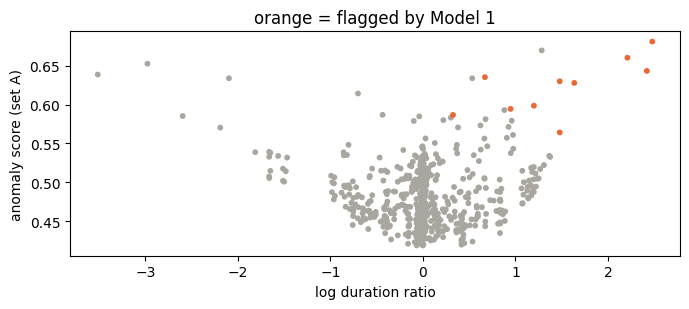

In [23]:
from sklearn.ensemble import IsolationForest
model = IsolationForest(n_estimators=300, random_state=0).fit(X_A)
score = -model.score_samples(X_A)                         # higher = more anomalous
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.scatter(feat["log_duration_ratio"], score, s=10, c=np.where(feat["rule_flag"], "#eb6834", "#a8a69f"))
ax.set_xlabel("log duration ratio"); ax.set_ylabel("anomaly score (set A)")
ax.set_title("orange = flagged by Model 1"); plt.tight_layout()

The most anomalous points are mostly the long runs - expected, because set A contains the duration. That is
**agreement with the rule, not validation**: both look at the same physics.

### Step 5 - Contamination is a choice, not a result

`contamination` tells the Isolation Forest which share of points to *call* anomalous. Fix 5 % and you get ~5 %
anomalies - whatever the data. It is therefore only swept:

In [24]:
if_res, if_sweep, if_sum = isolation_forest_check(feat, cfg)     # 10 seeds, both feature sets
if_sweep

,feature_set,contamination,flagged,rule_flags_covered,rule_flags_total,flagged_not_rule
0,A_duration_aware,0.01,7,4,10,3
1,A_duration_aware,0.02,14,8,10,6
2,A_duration_aware,0.05,34,10,10,24
3,A_duration_aware,0.10,67,10,10,57
4,B_context_only,0.01,7,1,10,6
5,B_context_only,0.02,14,2,10,12
6,B_context_only,0.05,34,2,10,32
7,B_context_only,0.10,67,4,10,63


### Step 6 - Evaluating a ranking without ground truth

* **Base rate:** share of rule-flagged rows. A random ranking scores about this much.
* **Average precision (AP):** how high the rule-flagged rows appear in the ranking (1 = all at the very top).
* The rule flags are **reference labels**, not truth. A "false positive" (ranked high, not flagged) may be a loss the
  rule missed - or a harmless rarity; a "false negative" (flagged, ranked low) shows what ML does not see. Precision
  and recall *against the truth* cannot be computed: there is no truth.
* **Stability:** overlap (Jaccard) of the top-10 lists between seeds.

In [25]:
print("base rate:", round(if_sum["base_rate"], 3))
pd.DataFrame({k: v for k, v in if_sum.items() if k != "base_rate"}).T.round(3)

base rate: 0.015


,average_precision_mean,average_precision_min,rule_flags_in_top_k_mean,top_k_jaccard_mean,top_k_jaccard_min
A_duration_aware,0.529,0.476,5.0,0.841,0.667
B_context_only,0.078,0.059,1.3,0.631,0.429


### Step 7 - K-Means

**Idea:** split the rows into k groups (**clusters**) so that rows in a group are close to their group centre. The
**silhouette** (-1 to 1) measures how well separated the groups are - values near 0 mean "no clear groups". The
**adjusted Rand index (ARI)** compares the grouping of two seeds (1 = identical). k is chosen by the silhouette.

,k,silhouette_mean,silhouette_min,ari_vs_seed0_min,best_cluster_size,rule_flags_in_best_cluster,best_cluster_purity
0,2,0.158,0.157,0.952,417,8,0.019
1,3,0.178,0.178,0.985,265,6,0.023
2,4,0.189,0.183,0.805,9,7,0.778
3,5,0.173,0.168,0.587,9,7,0.778
4,6,0.164,0.158,0.592,9,7,0.778
5,7,0.174,0.165,0.489,49,9,0.184
6,8,0.175,0.171,0.593,9,7,0.778


best k by silhouette: {'best_k_by_silhouette': 4, 'best_silhouette': 0.18865515350057474, 'best_k_ari_min': 0.8047930211208093, 'best_k_flag_cluster_purity': 0.7777777777777778, 'best_k_flags_in_cluster': 7}


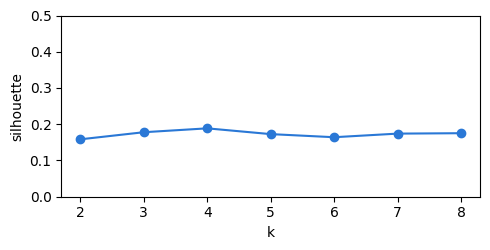

In [26]:
km, km_sum = kmeans_check(feat, cfg)
display(km.round(3))
plt.figure(figsize=(5, 2.6)); plt.plot(km["k"], km["silhouette_mean"], "o-", color="#2a78d6")
plt.xlabel("k"); plt.ylabel("silhouette"); plt.ylim(0, 0.5); plt.tight_layout()
print("best k by silhouette:", km_sum)

**How to read it:** the silhouette stays low for every k - the activations as a whole do not form well-separated
groups. At the best k, look at `best_cluster_size`, `rule_flags_in_best_cluster` and `ari_vs_seed0_min`: a small
cluster that holds most rule overruns and stays the same across seeds is a group of *long runs* - the same duration
information the rule uses. Its members that the rule did not flag are checked in step 9.

### Step 8 - Methodological checks

* **Independence:** rows are not independent - the same output repeats in every cycle and activations of one cycle
  influence each other. No statistical accuracy claim is made.
* **Leakage:** the duration ratio uses the median of the activation's own output, which includes that activation.
  Does that hide overruns? (leave-one-out check below)
* **Sample size:** a few hundred rows with 10 overruns - far too few for a supervised or deep model, and for any
  cross-validation.

In [27]:
print(feat.groupby("signal").size().describe().round(1)[["count", "min", "50%", "max"]])
loo = []
for r in feat[feat["rule_flag"]].itertuples():
    others = feat[(feat["signal"] == r.signal) & (feat["start"] != r.start)]["duration"]
    loo.append({"signal": r.signal, "start": round(r.start, 2), "ratio_incl_self": round(r.duration / r.median_duration_s, 2),
                "ratio_leave_one_out": round(r.duration / others.median(), 2)})
pd.DataFrame(loo)

count    38.0
min       8.0
50%      16.0
max      32.0
dtype: float64


,signal,start,ratio_incl_self,ratio_leave_one_out
0,WH.Q3_horRack,252.42,4.38,4.45
1,A1.7,254.15,1.95,1.96
2,WH.Q1_beltForward,291.28,9.11,9.14
3,WH.Q2_beltBackward,314.84,11.92,12.02
4,WH.Q1_beltForward,350.80,11.24,11.28
5,A0.7,363.10,1.38,1.39
6,A1.0,385.07,5.13,5.16
7,WH.Q7_cantForw,387.44,4.38,4.39
8,WH.Q3_horRack,452.99,3.32,3.37
9,WH.Q8_cantBack,468.45,2.58,2.58


### Step 9 - Are there new losses among the ML candidates?

Every activation in the top 20 of each Isolation Forest set, and every member of the K-Means cluster of long runs that
the rule did not flag, is checked against the evidence rules:

In [28]:
feat["kmeans_long_cluster"] = kmeans_long_cluster(feat, cfg, km_sum["best_k_by_silhouette"])
top_a = explain_rows(feat, "if_rank_A_duration_aware", 20, ctx["min_excess"]).assign(source="IF set A top 20")
top_b = explain_rows(feat, "if_rank_B_context_only", 20, ctx["min_excess"]).assign(source="IF set B top 20")
km_other = feat[feat["kmeans_long_cluster"] & ~feat["rule_flag"]].copy()
km_other["explanation"] = km_other.apply(explanation, axis=1, min_excess_s=ctx["min_excess"])
km_other["source"] = "K-Means long-run cluster, not rule-flagged"
cand = pd.concat([top_a, top_b, km_other[top_a.columns.intersection(km_other.columns).tolist()]])
display(cand.groupby(["source", "explanation"]).size().rename("items"))
print("unexplained, longer-than-normal candidates:", int((cand["explanation"] == UNEXPLAINED).sum()))

source                                      explanation                                                                                                               
IF set A top 20                             mild overrun below the detection limit (listed in sheet slow_steps)                                                            2
                                            restart directly after a stop window (part of that stop)                                                                       1
                                            rule overrun (also flagged by the engineering rule)                                                                            9
                                            truncated by a stop window (short by construction, no lost time)                                                               3
                                            within the normal range of this output (below its Tukey fence); ranked for its context (cycle pos

unexplained, longer-than-normal candidates: 0


**H10 (in this recording): not supported** if the count above is 0. The candidates are the rule's own events, runs
cut by a stop (unusual because they are *short*), mild overruns below the detection limit, or runs within their
normal range at an unusual moment - anomalies without lost time.

**What Model 2 contributed:** an independent multi-feature view in which the overruns are also the most isolated
points and the longest runs form their own cluster; and evidence that context alone reveals no additional loss.
**Why it is not the primary detector:** it adds no verifiable loss and its anomaly count depends on a parameter.
**What would make it useful:** many more recordings, downtime labels from operators or an MES, motion sensors on
belt and conveyor, documented signals.

### The Model 2 stage as one function, checked against the steps above

In [29]:
ctx2 = model2(ctx)
assert ctx2["ml"]["context_only_top20_unexplained_context"] == int(((top_a["explanation"] == UNEXPLAINED).sum()
                                                                   + (top_b["explanation"] == UNEXPLAINED).sum()))
assert ctx2["ml"]["kmeans_cluster_unexplained"] == int((km_other["explanation"] == UNEXPLAINED).sum())
print(ctx2["ml"]["decision"])

not retained: no verifiable additional loss beyond the engineering rule


### Model 2 in numbers

Anomaly counts, overlap with Model 1, additional candidates and independently verified additional losses - from
this notebook's own results. **Anomaly scores are rankings: they cannot be converted into lost seconds or
percentages without physical evidence**, so Model 2 reports no loss value.

In [30]:
rows = []
for fs, top in (("A_duration_aware", top_a), ("B_context_only", top_b)):
    sw = if_sweep[if_sweep["feature_set"] == fs]
    rule = int(top["explanation"].str.startswith("rule overrun").sum())
    rows.append({"feature set": fs,
                 "anomalies at contamination 0.01 / 0.02 / 0.05 / 0.10": " / ".join(map(str, sw["flagged"])),
                 "AP vs. rule flags": round(if_sum[fs]["average_precision_mean"], 3),
                 "top-20 = rule overruns": rule, "additional candidates (top 20)": len(top) - rule,
                 "longer than normal and unexplained": int((top["explanation"] == UNEXPLAINED).sum())})
rows.append({"feature set": "K-Means cluster of long runs", "top-20 = rule overruns": km_sum["best_k_flags_in_cluster"],
             "additional candidates (top 20)": len(km_other),
             "longer than normal and unexplained": int((km_other["explanation"] == UNEXPLAINED).sum())})
ml_counts = pd.DataFrame(rows)
ml_counts

,feature set,anomalies at contamination 0.01 / 0.02 / 0.05 / 0.10,AP vs. rule flags,top-20 = rule overruns,additional candidates (top 20),longer than normal and unexplained
0,A_duration_aware,7 / 14 / 34 / 67,0.529,9,11,0
1,B_context_only,7 / 14 / 34 / 67,0.078,2,18,0
2,K-Means cluster of long runs,NaN,NaN,7,2,0


In [31]:
# hand over to notebook 06: the Model 2 results
save_stage("05_model2", {k: ctx2[k] for k in ("feat", "if_res", "if_sweep", "km", "mlcmp", "km_members", "ml")})

**Next:** notebook 06 cross-checks Model 1 and Model 2 event by event and evaluates the cycle-level effect.